# 01 – Data Understanding: Explorative Datenanalyse (EDA)

**Projekt:** Intelligent EMS – Schweizer Day-Ahead-Preise verstehen und den Planungshorizont verlängern.

| Quelle (Fraunhofer ISE, CC BY 4.0) | Inhalt | Auflösung |
|---|---|---|
| [Energy-Charts – Pronovo CH](https://www.energy-charts.info/charts/power/chart.htm?l=de&c=CH&source=pronovo&interval=year) | Gemessene Nettoerzeugung, Last, Pumpspeicher-Verbrauch, Handel (MW), ab 2020 | 15 min |
| [Energy-Charts – Day-Ahead CH](https://www.energy-charts.info/charts/price_volume/chart.htm?l=de&c=CH&interval=year) | Auktionspreis (EUR/MWh), Handelsvolumen (MWh), ab 2015 | 60 min |

**Ausgangslage:** Die Preise für einen Liefertag werden bereits in der Auktion am Vortag festgelegt.
Nach Veröffentlichung sind die nächsten **24 Lieferstunden öffentlich bekannt**; dies ist ein
Liefertagesblock und nicht zu jeder Uhrzeit ein rollierendes Fenster von exakt 24 Stunden
(Zeitumstellung: 23/25 Stunden). Unser möglicher Mehrwert ist ein **48h-Profil: 24 h festgelegt +
24 h prognostiziert**, auf aufeinanderfolgende Liefertage ausgerichtet. Gegenüber einem EMS mit
bekannten Preisen ist nur der zusätzliche Nutzen des zweiten Tages der Prognose zuzuschreiben.

Die Auktion berücksichtigt **erwartete** Nachfrage und Produktion. Ein niedriger Mittagspreis bei
viel später gemessener PV ist mit erwarteter Sonne vereinbar, aber kein Beleg dafür, dass die
gleichzeitige Produktion einen schon festgelegten Preis verursacht. Wir betreiben ein
**Reverse-Engineering der Day-Ahead-Preisbildung**, nicht die Identifikation eines einzelnen
zentralen Preisprognosemodells. Korrelationen mit Ist-Daten beweisen weder Kausalität noch
Prognosegüte; Wetter-, Saison- und Nachfrageeffekte überlagern sich.

**Story:** Datenqualität → Preisniveau und Verteilung → Tages-/Wochenmuster → Schweizer
Erzeugung und Residuallast → Grenzen und Prognosebezug. Pronovo-Ist-Daten sind verzögert
veröffentlicht und keine verfügbaren Live-Features. Für den zweiten Tag braucht es am
Prognosezeitpunkt verfügbare **D+2-Prognosen** von Solar, Wind und Last; D+1-Prognosen reichen nicht.

**Reproduzieren:** Abhängigkeiten aus `notebooks/requirements.txt` installieren und alle Zellen
von oben nach unten ausführen (oder den Befehl im README verwenden). Der Berichtszeitraum ist
auf den 30.10.2026 begrenzt. Quellen-JSONs werden beim ersten Lauf unter
`data/raw/energy_charts_web/` gespeichert; weitere Läufe verwenden denselben Cache.
PNG-Dateien und berechnete Kennzahlen werden nach `figures/eda/` exportiert.

## 0 Setup

In [1]:
from __future__ import annotations

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from cycler import cycler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "energy_charts_web"
FIG = ROOT / "figures" / "eda"
RAW.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

TZ = "Europe/Zurich"
NOW = pd.Timestamp("2026-10-30", tz=TZ)
END = NOW.normalize() + pd.DateOffset(days=1)
PRICE_YEARS = range(2015, NOW.year + 1)    # Day-Ahead CH ab 2015 (wie analysis/06_zielwert.py)
POWER_YEARS = range(2020, NOW.year + 1)    # Pronovo-Daten gibt es auf Energy-Charts ab 2020

# Einheitlicher Grafikstil wie in analysis/common.py
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=COLORS),
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 1.5, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 100, "savefig.dpi": 180, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:,.2f}".format)


FIGURE_DESCRIPTIONS = {'00_datenqualitaet.png': 'Series coverage highlights schema changes; missing volume values occur at the daylight-saving transition.', '01_preis_zeitverlauf.png': 'The price level changes substantially over time, especially during the 2022 crisis; the centered mean is descriptive.', '02_preis_verteilung.png': 'The full distribution includes negative prices and price spikes; the median and zero line provide reference points.', '03_tagesprofile_perzentile.png': 'Seasonal price profiles show intraday patterns; shaded areas contain the middle 50% of observed prices.', '03b_tagesprofile_perzentile_ohne_2022_2023.png': 'Excluding 2022–2023 narrows the price bands while retaining seasonal intraday patterns.', '04_wochenmuster.png': 'Median prices vary by weekday, with a weekend dip most visible in spring and summer.', '05_tagesspanne.png': 'The daily high-to-low price spread varies by month and indicates gross, not guaranteed, flexibility value.', '07_pv_anteil.png': "Solar's share of measured generation has grown; 2026 covers only part of the year.", '08_strommix_monat.png': 'Separate generation lines show monthly source trends alongside load and net imports or exports.', '09_erzeugung_tagesprofil.png': 'Summer solar production has a strong daytime peak; profiles show observed generation, not auction-time forecasts.', '10_korrelationen.png': 'Residual load has the strongest Swiss rank association shown; correlation does not establish cause or forecast skill.', '11_scatter_treiber.png': 'Binned prices rise with residual load, fall with solar output, and vary little with Swiss net trade.', '12_solar_mittagspreis.png': 'Observed midday prices generally decline across higher Swiss solar-production bins; this is retrospective association.', '13_autokorrelation.png': 'Daily and weekly peaks show persistence in historical prices, providing reference lags for forecasting.', '14_residuallast_preis_tagesprofil.png': 'Summer midday residual load and fixed day-ahead prices dip together; this reflects patterns, not simultaneous causality.', '15_solar_wind.png': 'Measured Swiss solar is more strongly associated with price than Swiss wind, without proving forecast value.'}
FIGURE_INFO = {}


def save(fig, name: str, description: str | None = None) -> None:
    title = fig._suptitle.get_text() if fig._suptitle else next(
        (ax.get_title(loc="left") or ax.get_title(loc="center") or ax.get_title(loc="right")
         for ax in fig.axes if ax.get_title(loc="left") or ax.get_title(loc="center") or ax.get_title(loc="right")), ""
    )
    description = description or FIGURE_DESCRIPTIONS[name]
    if not title.strip() or not description.strip():
        raise ValueError(f"{name} must have a visible title and description")
    fig.text(0.01, 0.015, description, ha="left", va="bottom", fontsize=8.5,
             color=INK_2, wrap=True)
    fig.tight_layout(rect=(0, 0.12, 1, 0.95))
    fig.savefig(FIG / name)
    FIGURE_INFO[name] = {"title": title, "description": description}


## 1 Daten laden

Die Jahresdateien enthalten Reihen mit `name`, `data` und `xAxisValues` (Unix-Millisekunden, UTC).
Preis und Produktion werden separat geladen; die CH-Auktion wird explizit ausgewählt.
Wir prüfen HTTP-Fehler, verwenden einen lokalen Cache und begrenzen die Daten auf den
Berichtszeitraum. Der Cache hält einen Lauf reproduzierbar, garantiert aber keine unveränderliche
Quelle: Energy-Charts kann historische Werte nachträglich revidieren.

In [2]:
BASE = "https://www.energy-charts.info/charts"


def fetch_year(kind: str, path: str, year: int) -> list[dict]:
    cache = RAW / kind / f"{year}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    url = f"{BASE}/{path}".format(year=year)
    for attempt in range(4):
        r = requests.get(url, timeout=120)
        time.sleep(1)
        if r.status_code not in (429, 500, 502, 503, 504):
            break
        print(f"HTTP {r.status_code}: {url}; Versuch {attempt + 1}/4")
        time.sleep(5 * (attempt + 1))
    r.raise_for_status()
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(r.text, encoding="utf-8")
    return r.json()


def to_frame(series: list[dict]) -> pd.DataFrame:
    index = pd.to_datetime(series[0]["xAxisValues"], unit="ms", utc=True)
    cols = {s["name"]["de"] if isinstance(s["name"], dict) else s["name"][0]["de"]: s["data"] for s in series}
    return pd.DataFrame(cols, index=index).apply(pd.to_numeric, errors="raise")


def load(kind: str, path: str, years) -> tuple[pd.DataFrame, dict]:
    parts, meta = [], {}
    for y in years:
        series = fetch_year(kind, path, y)
        parts.append(to_frame(series))
        meta = {k: v for k, v in series[0].items() if k not in ("data", "xAxisValues")}
    df = pd.concat(parts).sort_index()
    duplicates = int(df.index.duplicated(keep="last").sum())
    print(f"{kind}: {duplicates} doppelte Zeitstempel an Jahresgrenzen zusammengeführt")
    df = df[~df.index.duplicated(keep="last")]
    df = df[df.index < END]
    df.index.name = "time_utc"
    return df, meta


power, power_meta = load("power_pronovo", "power/data/ch/year_pronovo_{year}.json", POWER_YEARS)
price, price_meta = load("price_dayahead", "price_volume/data/ch/year_dayahead_{year}.json", PRICE_YEARS)
print("Reihen in der Preisdatei:", list(price.columns))
# 2015–2017 enthält die Datei zusätzlich die Auktion IT-North-CH; für das Projekt zählt nur die CH-Auktion.
price = price[["Day Ahead Auktion (CH)", "Day Ahead Auktion (CH), Volumen"]].set_axis(["price", "volume"], axis=1)

print("Erzeugung:", power.shape, power.index.min(), "→", power.index.max())
print("  Datenquelle:", power_meta.get("datasource"), "|", power_meta.get("comment", [{}])[0].get("de"))
print("Preis/Volumen:", price.shape, price.index.min(), "→", price.index.max())
print("  Datenquelle:", price_meta.get("datasource"))

power_pronovo: 0 doppelte Zeitstempel an Jahresgrenzen zusammengeführt
price_dayahead: 0 doppelte Zeitstempel an Jahresgrenzen zusammengeführt
Reihen in der Preisdatei: ['Day Ahead Auktion (CH)', 'Day Ahead Auktion (IT-North-CH)', 'Day Ahead Auktion (CH), Volumen']
Erzeugung: (233756, 27) 2019-12-31 23:00:00+00:00 → 2026-08-31 21:45:00+00:00
  Datenquelle: Pronovo, ENTSO-E, BFE | Diese Daten werden mit einem Zeitversatz von einem Monat  veröffentlicht.
Preis/Volumen: (103704, 2) 2014-12-31 23:00:00+00:00 → 2026-10-30 22:00:00+00:00
  Datenquelle: ENTSO-E, EPEX SPOT


## 2 Datenqualität

### 2.1 Struktur, Datentypen und Kennzahlen

In [3]:
print("Spalten Erzeugung (MW):")
print(power.dtypes.to_string())
power.describe().T

Spalten Erzeugung (MW):
Grenzüberschreitender Stromhandel         float64
Wasser                                    float64
Biogas                                    float64
Biomasse                                  float64
Klärgas                                   float64
Energiepflanzen                           float64
Forst- und Landwirtschaftliche Abfälle    float64
Kehrichtverbrennung                       float64
Wind                                      float64
Photovoltaik                              float64
Last                                      float64
Abwasser                                  float64
Ausleitwasser                             float64
Dotierwasser                              float64
Durchlaufwasser                           float64
Pumpspeicher Erzeugung                    float64
Speicherwasser                            float64
Trinkwasser                               float64
Pumpspeicher Verbrauch                    float64
Kernenergie               

,count,mean,std,min,25%,50%,75%,max
Grenzüberschreitender Stromhandel,"233,750.00",-255.07,"2,368.92","-8,812.90","-1,751.50",62.40,"1,462.20","6,129.10"
Wasser,"35,136.00","4,105.69","1,933.07",988.70,"2,523.78","3,651.90","5,456.80","9,545.90"
Biogas,"222,144.00",33.97,4.29,20.60,30.60,34.30,37.00,47.70
Biomasse,"11,612.00",171.41,8.88,144.40,165.07,172.00,177.60,196.10
Klärgas,"222,144.00",11.49,1.57,5.90,10.50,11.50,12.50,19.20
Energiepflanzen,"93,604.00",3.54,2.17,0.20,1.00,4.00,5.60,7.30
Forst- und Landwirtschaftliche Abfälle,"67,200.00",45.12,13.39,15.60,33.80,46.10,54.00,76.10
Kehrichtverbrennung,"222,144.00",158.33,42.15,63.00,117.00,167.50,189.80,"1,519.00"
Wind,"233,756.00",17.53,15.63,0.00,5.40,12.00,25.90,84.80
Photovoltaik,"233,756.00",621.41,"1,102.15",0.00,0.00,10.10,833.30,"6,640.50"


In [4]:
price.describe().T

,count,mean,std,min,25%,50%,75%,max
price,"103,704.00",88.06,85.40,-463.68,37.74,58.09,109.64,871.61
volume,"103,692.00","2,880.78",783.14,952.90,"2,359.10","2,735.20","3,212.40","7,835.90"


### 2.2 Zeitliche Auflösung und Abdeckung

Die Auflösung wird aus dem Abstand zwischen zwei Zeitstempeln bestimmt. Seit 01.10.2025 handelt die gekoppelte
EU-Day-Ahead-Auktion 15-min-Produkte; geprüft wird, ob die CH-Reihe auf Energy-Charts das abbildet.

In [5]:
def resolution_table(df: pd.DataFrame) -> pd.DataFrame:
    step = df.index.to_series().diff().dt.total_seconds().div(60)
    year = df.index.tz_convert(TZ).year  # Jahre in Lokalzeit (wie im Chart)
    t = pd.DataFrame({"Auflösung [min]": step, "Jahr": year})
    out = t.groupby("Jahr")["Auflösung [min]"].agg(lambda s: s.value_counts().to_dict()).to_frame()
    out["Werte"] = t.groupby("Jahr").size()
    out["von (Lokalzeit)"] = df.index.tz_convert(TZ).to_series().groupby(year).min()
    out["bis (Lokalzeit)"] = df.index.tz_convert(TZ).to_series().groupby(year).max()
    return out


print("Preis:")
display(resolution_table(price))
print("Erzeugung:")
display(resolution_table(power))

Preis:


,Auflösung [min],Werte,von (Lokalzeit),bis (Lokalzeit)
Jahr,,,,
2015,{60.0: 8759},8760,2015-01-01 00:00:00+01:00,2015-12-31 23:00:00+01:00
2016,{60.0: 8784},8784,2016-01-01 00:00:00+01:00,2016-12-31 23:00:00+01:00
2017,{60.0: 8760},8760,2017-01-01 00:00:00+01:00,2017-12-31 23:00:00+01:00
2018,{60.0: 8760},8760,2018-01-01 00:00:00+01:00,2018-12-31 23:00:00+01:00
2019,{60.0: 8760},8760,2019-01-01 00:00:00+01:00,2019-12-31 23:00:00+01:00
2020,{60.0: 8784},8784,2020-01-01 00:00:00+01:00,2020-12-31 23:00:00+01:00
2021,{60.0: 8760},8760,2021-01-01 00:00:00+01:00,2021-12-31 23:00:00+01:00
2022,{60.0: 8760},8760,2022-01-01 00:00:00+01:00,2022-12-31 23:00:00+01:00
2023,{60.0: 8760},8760,2023-01-01 00:00:00+01:00,2023-12-31 23:00:00+01:00


Erzeugung:


,Auflösung [min],Werte,von (Lokalzeit),bis (Lokalzeit)
Jahr,,,,
2020,{15.0: 35135},35136,2020-01-01 00:00:00+01:00,2020-12-31 23:45:00+01:00
2021,{15.0: 35040},35040,2021-01-01 00:00:00+01:00,2021-12-31 23:45:00+01:00
2022,{15.0: 35040},35040,2022-01-01 00:00:00+01:00,2022-12-31 23:45:00+01:00
2023,{15.0: 35040},35040,2023-01-01 00:00:00+01:00,2023-12-31 23:45:00+01:00
2024,{15.0: 35136},35136,2024-01-01 00:00:00+01:00,2024-12-31 23:45:00+01:00
2025,{15.0: 35040},35040,2025-01-01 00:00:00+01:00,2025-12-31 23:45:00+01:00
2026,{15.0: 23324},23324,2026-01-01 00:00:00+01:00,2026-08-31 23:45:00+02:00


### 2.3 Fehlende Werte und Lücken

Wir zählen fehlende Zeitstempel auf dem UTC-Raster separat von fehlenden Werten je Spalte.
UTC vermeidet doppelte Lokalzeit-Stunden im Herbst; Profile verwenden Europe/Zurich.
Fehlende Erzeugungsreihen werden nicht pauschal als Null interpretiert.

In [6]:
def missing_report(df: pd.DataFrame, freq: str) -> pd.DataFrame:
    full = pd.date_range(df.index.min(), df.index.max(), freq=freq, tz="UTC")
    missing_ts = full.difference(df.index)
    print(f"Zeitstempel im {freq}-Raster: {len(full):,}, vorhanden: {len(df):,}, fehlend: {len(missing_ts):,}")
    if len(missing_ts):
        print("  erste fehlende:", list(missing_ts[:5]))
    na = df.isna().groupby(df.index.tz_convert(TZ).year).sum()
    return na.loc[:, na.sum() > 0] if (na.sum() > 0).any() else pd.DataFrame({"NaN": ["keine"]})


print("Preis:")
display(missing_report(price, "1h"))
print("Erzeugung (NaN durch Schema-Änderungen 2020/2021 siehe 2.4):")
display(missing_report(power, "15min"))

Preis:
Zeitstempel im 1h-Raster: 103,704, vorhanden: 103,704, fehlend: 0


,volume
time_utc,
2015,1
2016,1
2017,1
2018,1
2019,1
2020,1
2021,1
2022,1
2023,1


Erzeugung (NaN durch Schema-Änderungen 2020/2021 siehe 2.4):
Zeitstempel im 15min-Raster: 233,756, vorhanden: 233,756, fehlend: 0


,Grenzüberschreitender Stromhandel,Wasser,Biogas,Biomasse,Klärgas,Energiepflanzen,Forst- und Landwirtschaftliche Abfälle,Kehrichtverbrennung,Abwasser,Ausleitwasser,...,Trinkwasser,Pumpspeicher Verbrauch,Kernenergie,Erdgas Dampfturbine,Gas- und Dampfkombikraftwerk,Gasturbine,Verbrennungsmotor,Holzenergie,Gasförmige fossile Energieträger,Flüssige fossile Energieträger
time_utc,,,,,,,,,,,,,,,,,,,,,
2020,0,0,11612,23524,11612,11612,11612,11612,35136,35136,...,35136,35136,35136,35136,35136,35136,35136,35136,35136,35136
2021,0,35040,0,35040,0,0,0,0,0,0,...,0,35040,35040,35040,35040,35040,35040,35040,35040,35040
2022,0,35040,0,35040,0,0,35040,0,0,0,...,0,26204,26204,26204,26204,26204,26204,35040,35040,35040
2023,0,35040,0,35040,0,35040,26404,0,0,0,...,0,0,0,26404,26404,26404,26404,8636,8636,8636
2024,0,35136,0,35136,0,35136,35136,0,0,0,...,0,0,0,35136,35136,35136,35136,0,0,0
2025,3,35040,0,35040,0,35040,35040,0,0,0,...,0,0,0,35040,35040,35040,35040,0,0,0
2026,3,23324,0,23324,0,23324,23324,0,0,0,...,0,0,0,23324,23324,23324,23324,0,0,0


### 2.4 Schema und Vollständigkeit

**Grafik: Datenabdeckung und fehlende Werte.** Die Farbmatrix zeigt den Anteil vorhandener
Pronovo-Werte je Reihe und Jahr. Der zweite Teil zählt fehlende Preise und Volumenwerte;
so sind Schemawechsel von einzelnen fehlenden Messwerten unterscheidbar.

In [7]:
coverage = power.notna().groupby(power.index.tz_convert(TZ).year).mean().T
coverage.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

time_utc,2020,2021,2022,2023,2024,2025,2026
Grenzüberschreitender Stromhandel,100%,100%,100%,100%,100%,100%,100%
Wasser,100%,0%,0%,0%,0%,0%,0%
Biogas,67%,100%,100%,100%,100%,100%,100%
Biomasse,33%,0%,0%,0%,0%,0%,0%
Klärgas,67%,100%,100%,100%,100%,100%,100%
Energiepflanzen,67%,100%,100%,0%,0%,0%,0%
Forst- und Landwirtschaftliche Abfälle,67%,100%,0%,25%,0%,0%,0%
Kehrichtverbrennung,67%,100%,100%,100%,100%,100%,100%
Wind,100%,100%,100%,100%,100%,100%,100%
Photovoltaik,100%,100%,100%,100%,100%,100%,100%


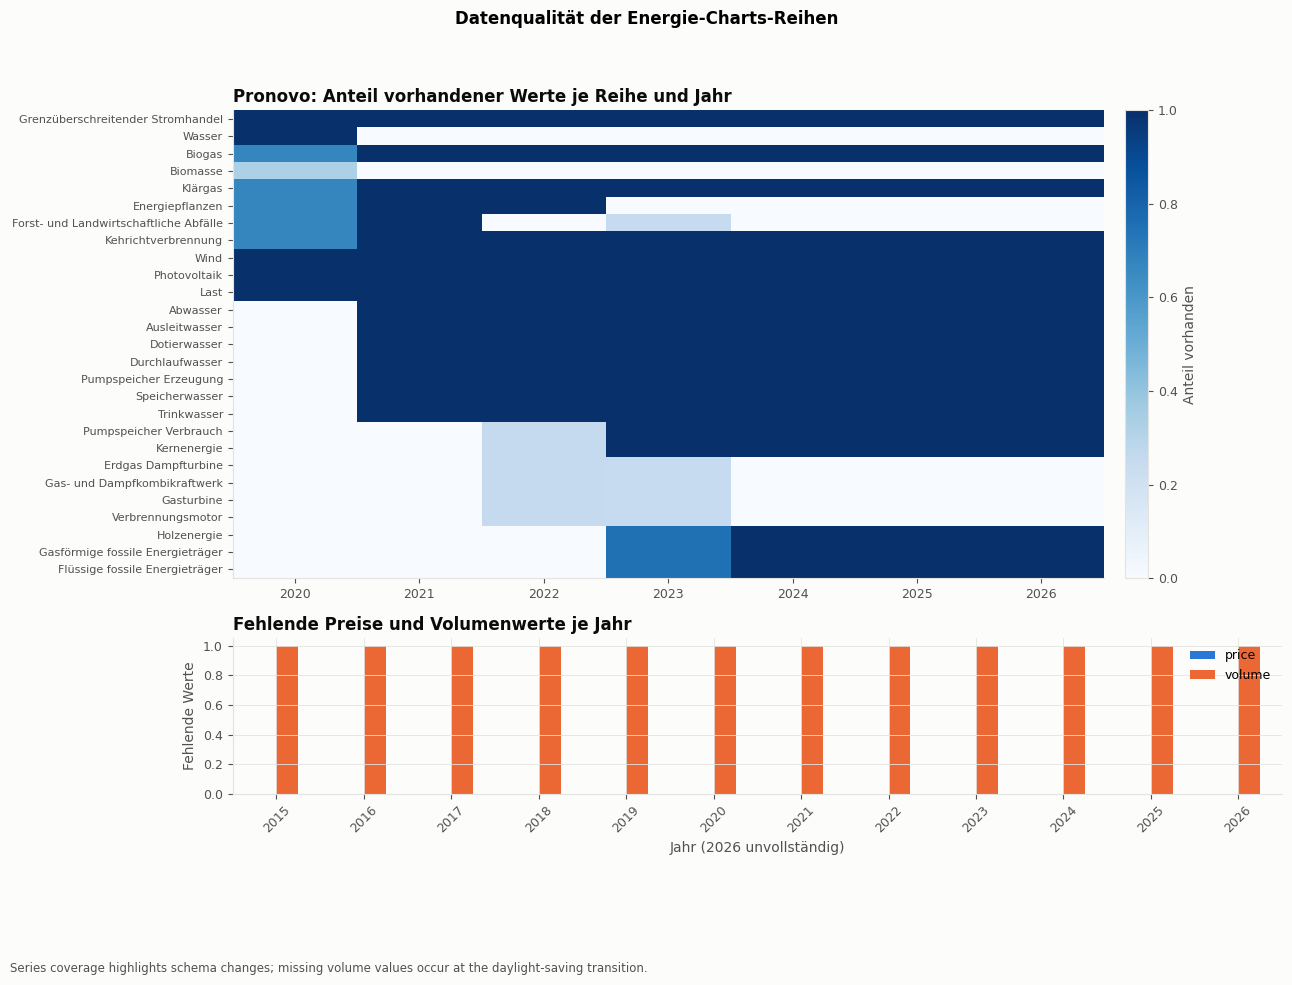

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10), gridspec_kw={"height_ratios": [3, 1]})
image = axes[0].imshow(coverage.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="Blues")
axes[0].set_yticks(range(len(coverage)), coverage.index, fontsize=8)
axes[0].set_xticks(range(len(coverage.columns)), coverage.columns)
axes[0].set_title("Pronovo: Anteil vorhandener Werte je Reihe und Jahr")
axes[0].grid(False)
fig.colorbar(image, ax=axes[0], label="Anteil vorhanden", pad=0.02)
missing_y = price.isna().groupby(price.index.tz_convert(TZ).year).sum()
missing_y.plot.bar(ax=axes[1], color=[COLORS[0], COLORS[1]], rot=45)
axes[1].set_title("Fehlende Preise und Volumenwerte je Jahr")
axes[1].set_xlabel("Jahr (2026 unvollständig)")
axes[1].set_ylabel("Fehlende Werte")
fig.suptitle("Datenqualität der Energie-Charts-Reihen", fontweight="bold")
save(fig, "00_datenqualitaet.png", "Series coverage highlights schema changes; missing volume values occur at the daylight-saving transition.")

**Konsequenz:** 2020 gibt es nur „Wasser“ gesamt; Kernenergie und Pumpspeicher-Verbrauch fehlen bis
30.09.2022; die Kategorien für Biomasse und fossile Kraftwerke werden im Oktober 2022 und im April 2023 umbenannt.
Vollständig ist der Datensatz deshalb erst **ab 01.10.2022** (Jahresvergleiche ab 2023). Davor würde z. B. der
fehlende Kernkraftblock (~20 TWh/Jahr) als scheinbarer Produktionseinbruch erscheinen. Die Gruppierung in
Abschnitt 4 fasst die umbenannten Kategorien zusammen.

### 2.5 Effektive Auflösung der Erzeugungsreihen

Einige Reihen sind zwar im 15-min-Raster abgelegt, ändern sich aber nur einmal pro Stunde (die Stundenwerte
werden viermal wiederholt). Das ist für die Modellierung wichtig: Diese Reihen enthalten keine 15-min-Information.

In [9]:
def changes_per_hour(s: pd.Series) -> float:
    # Anteil der 15-min-Schritte innerhalb einer Stunde, in denen sich der Wert ändert (0 = nur stündlich)
    inner = s.index.minute != 0
    return float((s.diff().ne(0) & inner).sum() / inner.sum())


eff = pd.Series({c: changes_per_hour(power[c].dropna()) for c in power}).sort_values()
eff.to_frame("Anteil Änderungen innerhalb der Stunde").style.format("{:.0%}")

,Anteil Änderungen innerhalb der Stunde
Last,0%
Flüssige fossile Energieträger,13%
Grenzüberschreitender Stromhandel,15%
Gas- und Dampfkombikraftwerk,26%
Abwasser,44%
Dotierwasser,47%
Photovoltaik,51%
Gasturbine,53%
Energiepflanzen,54%
Erdgas Dampfturbine,54%


### 2.6 Ausreisser und Extremwerte im Preis

Negative Preise und Preisspitzen werden markiert, aber nicht automatisch entfernt.
Die Tabelle zählt negative Werte, Werte über 300 EUR/MWh und Werte ausserhalb
P25 − 3 × IQR bzw. P75 + 3 × IQR je Jahr. Solche Werte sind wirtschaftlich plausibel;
ohne unabhängige Quelle lässt sich jedoch nicht jeder Extremwert als fehlerfrei bestätigen.

In [10]:
# Einheitliches Stundenraster; Volumen-NaN bleiben auch nach Aggregation sichtbar.
price_h = price.resample("1h").agg({"price": "mean", "volume": lambda s: s.sum(min_count=1)}).dropna(subset=["price"])
local = price_h.index.tz_convert(TZ)
price_h["year"], price_h["month"], price_h["hour"] = local.year, local.month, local.hour
price_h["weekend"] = local.day_of_week >= 5
price_h["season"] = price_h["month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Frühling", 4: "Frühling",
                                          5: "Frühling", 6: "Sommer", 7: "Sommer", 8: "Sommer", 9: "Herbst",
                                          10: "Herbst", 11: "Herbst"})

g = price_h.groupby("year")["price"]
q1, q3 = g.quantile(0.25), g.quantile(0.75)
yearly = pd.DataFrame({
    "Mittel": g.mean(), "Median": g.median(), "Std": g.std(), "Min": g.min(), "Max": g.max(),
    "Std. < 0 €": g.apply(lambda s: (s < 0).sum()),
    "Std. > 300 €": g.apply(lambda s: (s > 300).sum()),
    "IQR-Ausreisser": [((s < q1[y] - 3 * (q3[y] - q1[y])) | (s > q3[y] + 3 * (q3[y] - q1[y]))).sum()
                       for y, s in g],
    "Stunden": g.size(),
})
yearly

,Mittel,Median,Std,Min,Max,Std. < 0 €,Std. > 300 €,IQR-Ausreisser,Stunden
year,,,,,,,,,
2015,40.30,40.94,13.15,-11.66,114.98,9,0,1,8760
2016,37.88,34.33,16.78,-45.68,120.90,24,0,11,8784
2017,46.00,41.25,19.60,-49.95,179.92,5,0,43,8760
2018,52.22,51.36,16.43,-30.62,161.35,29,0,12,8760
2019,40.92,39.97,12.33,-39.45,108.11,17,0,19,8760
2020,34.00,34.59,14.75,-59.61,126.70,75,0,39,8784
2021,114.94,79.68,83.94,-79.40,532.21,41,402,26,8760
2022,281.65,251.30,128.20,-1.00,871.61,1,3132,2,8760
2023,107.47,106.47,40.47,-142.88,268.80,76,0,12,8760


## 3 EDA Börsenstrompreis und Handelsvolumen

### 3.1 Gesamte Preiszeitreihe

**Grafik: CH-Day-Ahead-Preis 2015–2026.** Tagesmittel und ein zentriertes 30-Tage-Mittel
zeigen Niveauwechsel, besonders die Energiekrise 2022. Die Glättung dient nur der
Beschreibung und wird nicht als Prognose-Feature verwendet.

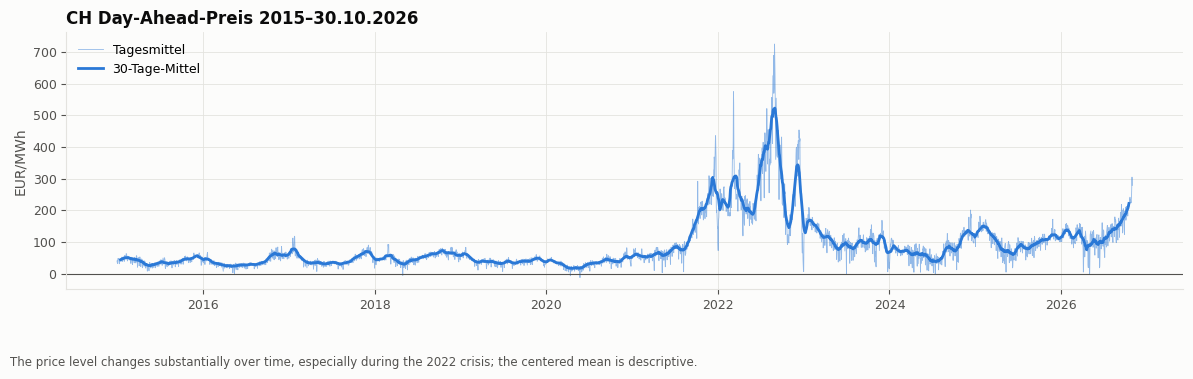

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
daily = price_h["price"].tz_convert(TZ).resample("D").mean()
ax.plot(daily.index, daily, color=COLORS[0], linewidth=0.6, alpha=0.5, label="Tagesmittel")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=COLORS[0], linewidth=2, label="30-Tage-Mittel")
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("CH Day-Ahead-Preis 2015–30.10.2026")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left")
save(fig, "01_preis_zeitverlauf.png", "The price level changes substantially over time, especially during the 2022 crisis; the centered mean is descriptive.")

### 3.2 Preisverteilung und Extremwerte

**Grafik: Preisverteilung der letzten 24 Monate.** Das Histogramm zeigt alle Stunden,
einschliesslich negativer Preise und Spitzen, ohne Clipping. Die Extremwertzählung oben
und die gesamte Zeitreihe ersetzen die redundanten Jahres-Boxplots.

N=17,521, negative Stunden=542, Min=-463.68, Max=596.70, Schiefe=-0.51, Kurtosis=5.82


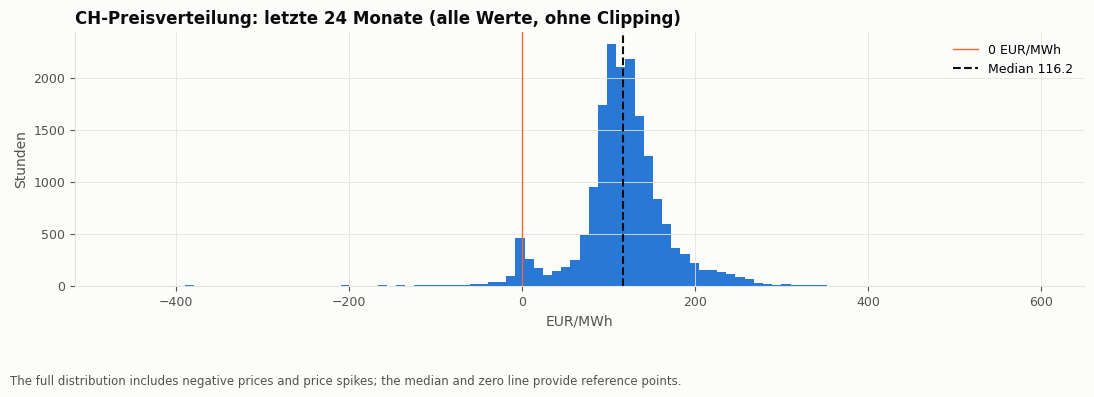

In [12]:
recent = price_h.loc[price_h.index >= price_h.index.max() - pd.Timedelta(days=730), "price"]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.hist(recent, bins=100, color=COLORS[0])
ax.axvline(0, color=COLORS[1], linewidth=1, label="0 EUR/MWh")
ax.axvline(recent.median(), color=INK, linestyle="--", label=f"Median {recent.median():.1f}")
ax.set_title("CH-Preisverteilung: letzte 24 Monate (alle Werte, ohne Clipping)")
ax.set_xlabel("EUR/MWh")
ax.set_ylabel("Stunden")
ax.legend()
save(fig, "02_preis_verteilung.png", "The full distribution includes negative prices and price spikes; the median and zero line provide reference points.")
print(f"N={len(recent):,}, negative Stunden={(recent < 0).sum():,}, "
      f"Min={recent.min():.2f}, Max={recent.max():.2f}, "
      f"Schiefe={recent.skew():.2f}, Kurtosis={recent.kurt():.2f}")

### 3.3 Tages- und Saisonmuster

**Grafik: Saisonale Tagesprofile.** Linie = Median (P50), Band = P25–P75, also die
mittleren 50 % der Beobachtungen, nicht ±25 % des Medianwerts und kein Konfidenzintervall.
Werktage (Mo–Fr, inklusive Feiertage) und Wochenenden werden getrennt dargestellt.
Die zweite Grafik prüft die Robustheit ohne die Hochpreisjahre 2022–2023.

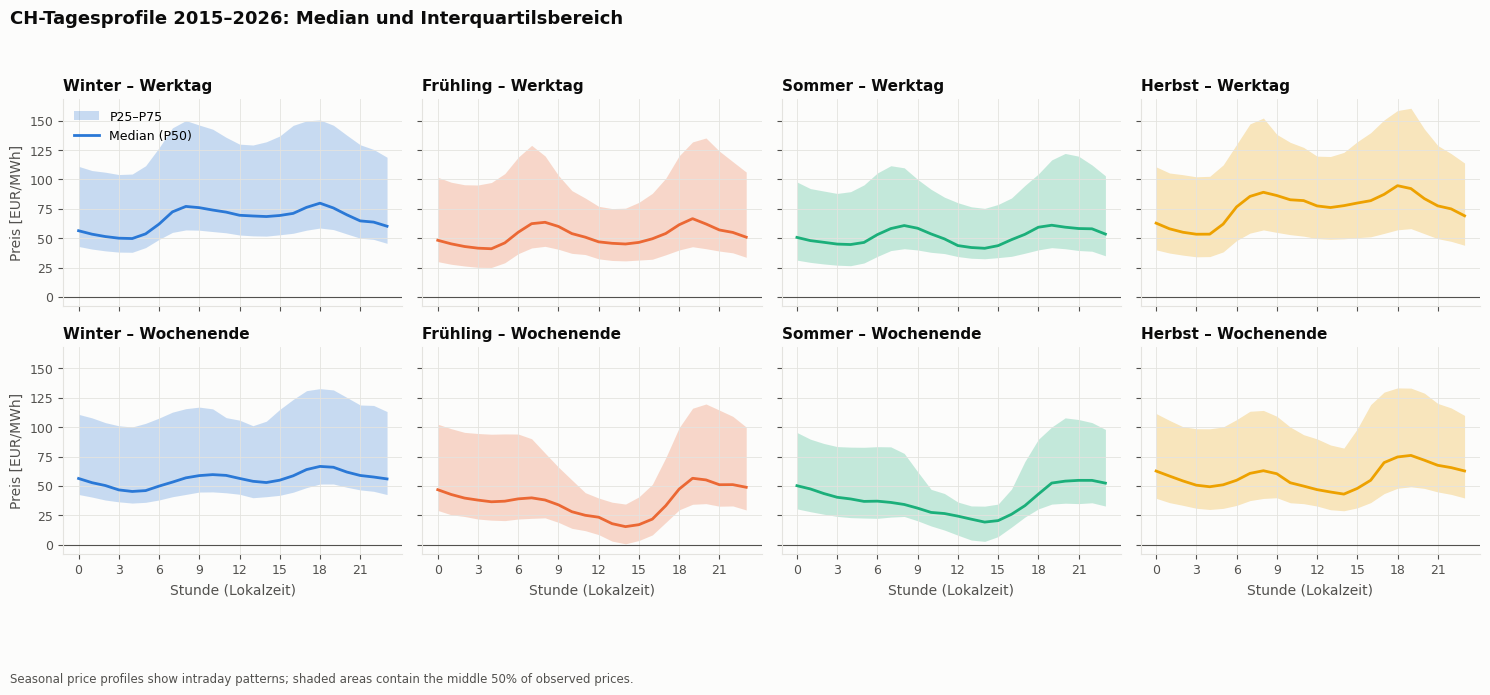

In [13]:
recent_h = price_h[price_h.index >= pd.Timestamp("2024-01-01", tz="UTC")]
SEASON_ORDER = ["Winter", "Frühling", "Sommer", "Herbst"]


def profile_quantiles(df: pd.DataFrame) -> pd.DataFrame:
    # P25/P50/P75 je Tagtyp, Saison und Stunde
    q = df.groupby(["weekend", "season", "hour"])["price"].quantile([0.25, 0.5, 0.75]).unstack()
    q.columns = ["P25", "P50", "P75"]
    return q


def plot_profiles(df: pd.DataFrame, title: str, name: str) -> pd.DataFrame:
    q = profile_quantiles(df)
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
    for r, (weekend, day) in enumerate(((False, "Werktag"), (True, "Wochenende"))):
        for c, season in enumerate(SEASON_ORDER):
            ax, p = axes[r, c], q.loc[(weekend, season)]
            ax.fill_between(p.index, p["P25"], p["P75"], color=COLORS[c], alpha=0.25, linewidth=0,
                            label="P25–P75")
            ax.plot(p.index, p["P50"], color=COLORS[c], linewidth=2, label="Median (P50)")
            ax.axhline(0, color=INK_2, linewidth=0.8)
            ax.set_title(f"{season} – {day}", fontsize=11)
            ax.set_xticks(range(0, 24, 3))
            if r == 1:
                ax.set_xlabel("Stunde (Lokalzeit)")
        axes[r, 0].set_ylabel("Preis [EUR/MWh]")
    axes[0, 0].legend(loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    save(fig, name, FIGURE_DESCRIPTIONS[name])
    return q


years_all = f"{price_h['year'].min()}–{price_h['year'].max()}"
q_all = plot_profiles(price_h, f"CH-Tagesprofile {years_all}: Median und Interquartilsbereich",
                      "03_tagesprofile_perzentile.png")

,IQR-Breite mit 2022–23,IQR-Breite ohne 2022–23,Median-Tagesspanne ohne 2022–23
season,,,
Winter,75.29,45.64,22.24
Frühling,64.42,39.79,25.66
Sommer,56.73,41.24,21.20
Herbst,75.49,63.65,29.90


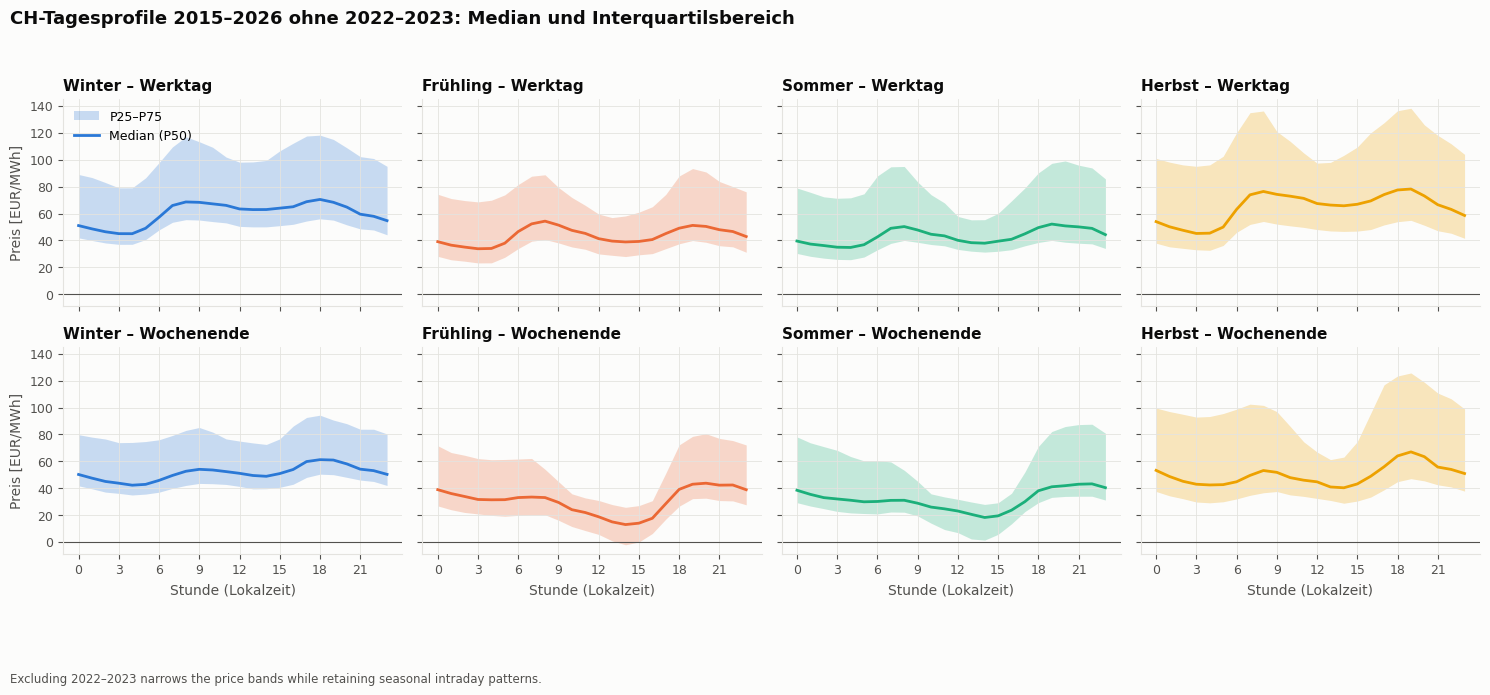

In [14]:
no_crisis = price_h[~price_h["year"].isin([2022, 2023])]
q_nc = plot_profiles(no_crisis, f"CH-Tagesprofile {years_all} ohne 2022–2023: Median und Interquartilsbereich",
                     "03b_tagesprofile_perzentile_ohne_2022_2023.png")

# Vergleich: mittlere Breite des Interquartilsbereichs je Saison
width = pd.DataFrame({
    "IQR-Breite mit 2022–23": (q_all["P75"] - q_all["P25"]).groupby(level="season").mean(),
    "IQR-Breite ohne 2022–23": (q_nc["P75"] - q_nc["P25"]).groupby(level="season").mean(),
    "Median-Tagesspanne ohne 2022–23": q_nc["P50"].groupby(level=["weekend", "season"]).agg(
        lambda s: s.max() - s.min()).groupby(level="season").mean(),
}).loc[SEASON_ORDER]
width

In [15]:
profile_hours = q_nc["P50"].unstack("hour")
profile_summary = pd.DataFrame({
    "Minimum [EUR/MWh]": profile_hours.min(axis=1),
    "Stunde Minimum": profile_hours.idxmin(axis=1),
    "Maximum [EUR/MWh]": profile_hours.max(axis=1),
    "Stunde Maximum": profile_hours.idxmax(axis=1),
    "Spanne Medianprofil [EUR/MWh]": profile_hours.max(axis=1) - profile_hours.min(axis=1),
})
display(profile_summary)

Minimum [EUR/MWh]  Stunde Minimum  Maximum [EUR/MWh]  \
weekend season                                                           
False   Frühling              33.78               3              54.32   
        Herbst                45.16               3              78.23   
        Sommer                34.74               4              52.14   
        Winter                44.99               4              70.48   
True    Frühling              12.93              14              43.72   
        Herbst                40.30              14              67.02   
        Sommer                18.21              14              43.22   
        Winter                42.23               4              61.21   

                  Stunde Maximum  Spanne Medianprofil [EUR/MWh]  
weekend season                                                   
False   Frühling               8                          20.54  
        Herbst                19                          33.07  
        Sommer                19                          17.40  
        Winter                18                          25.49  
True    Frühling              20                          30.79  
        Herbst                19                          26.72  
        Sommer                22                          25.01  
        Winter                18                          18.98

**Interpretation:** Die Tagesform verbindet erwartete Nachfrage (morgens/abends) und
erwartete Produktion (PV mittags). Das Mittagstal ist im Sommer ausgeprägter als im Winter
und an Wochenenden oft tiefer. Die Profile mischen unterschiedliche Preisregime;
das Weglassen von 2022–2023 ist eine Sensitivitätsanalyse, keine Empfehlung, diese Jahre
ungeprüft aus dem Training zu löschen. Die nachfolgenden Tabellen quantifizieren die Form.

### 3.4 Volatilität und bereits bekannte Optimierungsmöglichkeiten

**Grafik: Mittlere tägliche Preisspanne je Monat.** Maximum minus Minimum misst eine
theoretische Brutto-Gelegenheit, keine realisierbare Einsparung. Der Preis des ersten
Liefertages ist bereits bekannt. Prognosen können nur die Planung darüber hinaus
verbessern; Batterieverluste, Leistung, Kapazität und Endkundentarife reduzieren den Nutzen.

,Ø Spanne,Median,max. Spanne
time_utc,,,
2015,24.03,23.10,70.92
2016,22.12,18.75,76.42
2017,24.09,20.58,101.34
2018,24.62,23.35,102.30
2019,19.81,18.74,70.48
2020,21.57,18.56,86.46
2021,56.72,38.68,214.18
2022,126.42,110.28,368.00
2023,62.42,54.16,235.30


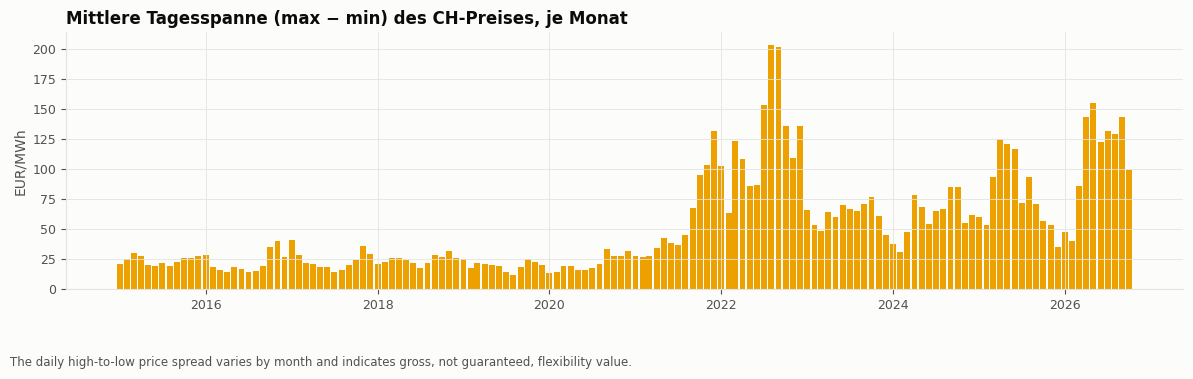

In [16]:
spread = price_h["price"].tz_convert(TZ).resample("D").agg(lambda s: s.max() - s.min())
fig, ax = plt.subplots(figsize=(12, 4))
monthly_spread = spread.resample("MS").mean()
ax.bar(monthly_spread.index, monthly_spread, width=25, color=COLORS[3])
ax.set_title("Mittlere Tagesspanne (max − min) des CH-Preises, je Monat")
ax.set_ylabel("EUR/MWh")
save(fig, "05_tagesspanne.png", "The daily high-to-low price spread varies by month and indicates gross, not guaranteed, flexibility value.")
spread.groupby(spread.index.year).agg(["mean", "median", "max"]).rename(
    columns={"mean": "Ø Spanne", "median": "Median", "max": "max. Spanne"})

### 3.5 Wochenmuster (ab 2024)

**Grafik: Preisniveau nach Wochentag.** Medianlinie und P25–P75 je Saison zeigen die
Wochenstruktur ohne Boxplots. Feiertage bleiben beim jeweiligen Wochentag;
die Bänder beschreiben Streuung, keine Unsicherheit einer Prognose.

,median,mean,count
weekday,,,
0,105.19,106.83,3551
1,107.99,110.22,3552
2,107.27,111.29,3552
3,105.82,108.45,3552
4,103.14,105.94,3552
5,94.91,87.70,3528
6,87.07,78.18,3528


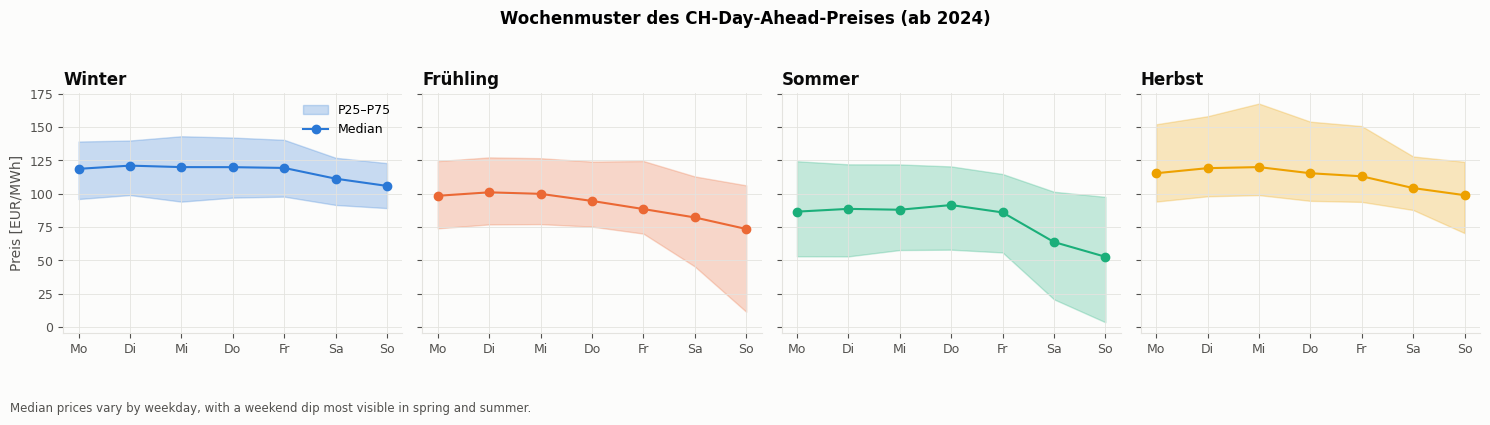

In [17]:
week = recent_h.copy()
week["weekday"] = week.index.tz_convert(TZ).day_of_week
week_q = week.groupby(["season", "weekday"])["price"].quantile([0.25, 0.5, 0.75]).unstack()
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
for ax, season, color in zip(axes, SEASON_ORDER, COLORS):
    q = week_q.loc[season]
    ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.25, label="P25–P75")
    ax.plot(q.index, q[0.5], color=color, marker="o", label="Median")
    ax.set_xticks(range(7), ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"])
    ax.set_title(season)
axes[0].set_ylabel("Preis [EUR/MWh]")
axes[0].legend()
fig.suptitle("Wochenmuster des CH-Day-Ahead-Preises (ab 2024)", fontweight="bold")
save(fig, "04_wochenmuster.png", "Median prices vary by weekday, with a weekend dip most visible in spring and summer.")
display(week.groupby("weekday")["price"].agg(["median", "mean", "count"]))

## 4 EDA Stromproduktion Schweiz (Pronovo)

### 4.1 Gruppierung der Energieträger

Pronovo unterscheidet die Wasserkraft sehr fein. Für die Analyse fassen wir die Reihen zu Gruppen zusammen.
Pumpspeicher-Verbrauch ist negativ, der grenzüberschreitende Handel ist positiv bei Nettoimport.

In [18]:
GROUPS = {
    "Wasser (nur 2020)": ["Wasser"],
    "Laufwasser": ["Durchlaufwasser", "Ausleitwasser", "Dotierwasser", "Trinkwasser", "Abwasser"],
    "Speicherwasser": ["Speicherwasser"],
    "Pumpspeicher": ["Pumpspeicher Erzeugung"],
    "Kernenergie": ["Kernenergie"],
    "Photovoltaik": ["Photovoltaik"],
    "Wind": ["Wind"],
    "Biomasse/Abfall": ["Biogas", "Klärgas", "Holzenergie", "Kehrichtverbrennung", "Biomasse", "Energiepflanzen",
                        "Forst- und Landwirtschaftliche Abfälle"],
    "Fossil": ["Gasförmige fossile Energieträger", "Flüssige fossile Energieträger", "Erdgas Dampfturbine",
               "Gas- und Dampfkombikraftwerk", "Gasturbine", "Verbrennungsmotor"],
}
known = {c for cols in GROUPS.values() for c in cols} | {"Pumpspeicher Verbrauch", "Last",
                                                         "Grenzüberschreitender Stromhandel"}
print("Nicht zugeordnete Spalten:", sorted(set(power.columns) - known) or "keine")

gen_all = pd.DataFrame({g: power[[c for c in cols if c in power]].sum(axis=1, min_count=1)
                        for g, cols in GROUPS.items()})
# Ab hier nur Jahre mit vollständigem Schema (siehe 2.4)
FULL_FROM = pd.Timestamp("2022-10-01", tz=TZ)
power = power[power.index >= FULL_FROM]
gen = gen_all[gen_all.index >= FULL_FROM].drop(columns="Wasser (nur 2020)")
step_h = 0.25  # 15-min-Werte in MW → Energie in MWh
gen.head()

Nicht zugeordnete Spalten: keine


,Laufwasser,Speicherwasser,Pumpspeicher,Kernenergie,Photovoltaik,Wind,Biomasse/Abfall,Fossil
time_utc,,,,,,,,
2022-09-30 22:00:00+00:00,"1,786.70",313.70,347.60,"2,944.80",0.00,17.00,222.30,12.30
2022-09-30 22:15:00+00:00,"1,781.90",312.40,355.00,"2,946.00",0.00,16.40,223.80,12.20
2022-09-30 22:30:00+00:00,"1,756.80",296.40,309.40,"2,947.00",0.00,18.70,224.50,12.40
2022-09-30 22:45:00+00:00,"1,722.50",255.80,211.40,"2,947.40",0.00,17.90,222.80,11.70
2022-09-30 23:00:00+00:00,"1,727.70",243.20,297.50,"2,946.90",0.00,24.90,222.70,11.60


### 4.2 Strommix je Jahr (TWh)

Wegen der Schema-Änderungen (2.4) erst ab 2023 (ganze Jahre). Das laufende Jahr ist nur bis zum letzten publizierten Monat vorhanden (Pronovo-Daten erscheinen mit
einem Monat Verzögerung) und deshalb nicht direkt mit den vollen Jahren vergleichbar.

In [19]:
year_loc = power.index.tz_convert(TZ).year
energy_y = ((gen * step_h).groupby(year_loc).sum() / 1e6).loc[2023:]  # TWh
load_y = ((power["Last"] * step_h).groupby(year_loc).sum() / 1e6).loc[2023:]
pump_y = ((power["Pumpspeicher Verbrauch"] * step_h).groupby(year_loc).sum() / 1e6).loc[2023:]

table = energy_y.copy()
table["Summe Erzeugung"] = energy_y.sum(axis=1)
table["Last"] = load_y
table["Pumpspeicher Verbrauch"] = pump_y
table["PV-Anteil %"] = 100 * energy_y["Photovoltaik"] / table["Summe Erzeugung"]
table

,Laufwasser,Speicherwasser,Pumpspeicher,Kernenergie,Photovoltaik,Wind,Biomasse/Abfall,Fossil,Summe Erzeugung,Last,Pumpspeicher Verbrauch,PV-Anteil %
time_utc,,,,,,,,,,,,
2023,15.09,8.96,11.01,23.37,4.91,0.17,2.62,0.22,66.35,61.07,-2.92,7.41
2024,16.86,11.22,11.83,22.30,5.96,0.16,2.56,0.19,71.09,59.63,-2.46,8.39
2025,13.32,8.43,9.65,17.00,7.95,0.16,2.51,0.15,59.16,62.07,-3.39,13.43
2026,7.88,4.92,7.66,12.01,7.77,0.10,1.73,0.11,42.19,42.32,-2.72,18.41


### 4.3 PV-Ausbau und Vergleichbarkeit

**Grafik: PV-Anteil an der Schweizer Erzeugung.** Ganze Jahre werden mit ganzen Jahren
verglichen; das letzte, unvollständige Jahr ist separat markiert. Sein Anteil hängt auch
von der saisonalen Abdeckung ab und darf nicht als Jahreswachstum interpretiert werden.

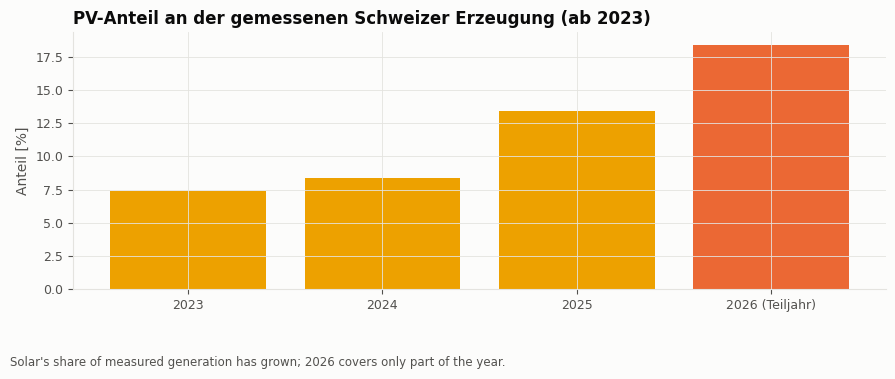

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{y}" + (" (Teiljahr)" if y == NOW.year else "") for y in table.index]
ax.bar(labels, table["PV-Anteil %"], color=[COLORS[3] if y < NOW.year else COLORS[1] for y in table.index])
ax.set_title("PV-Anteil an der gemessenen Schweizer Erzeugung (ab 2023)")
ax.set_ylabel("Anteil [%]")
save(fig, "07_pv_anteil.png", "Solar's share of measured generation has grown; 2026 covers only part of the year.")

### 4.4 Saisonalität: Erzeugung und Handel

**Grafik: Monatliche Erzeugung je Energieträger, Last und Handelssaldo.** Jede
Erzeugungsart hat eine eigene Linie statt gestapelter Flächen. Positive Handelswerte
bedeuten Nettoimport, negative Nettoexport. Die saisonale Bilanz motiviert die Analyse
der Nachbarmärkte, beweist für sich allein aber keinen Preiseinfluss.

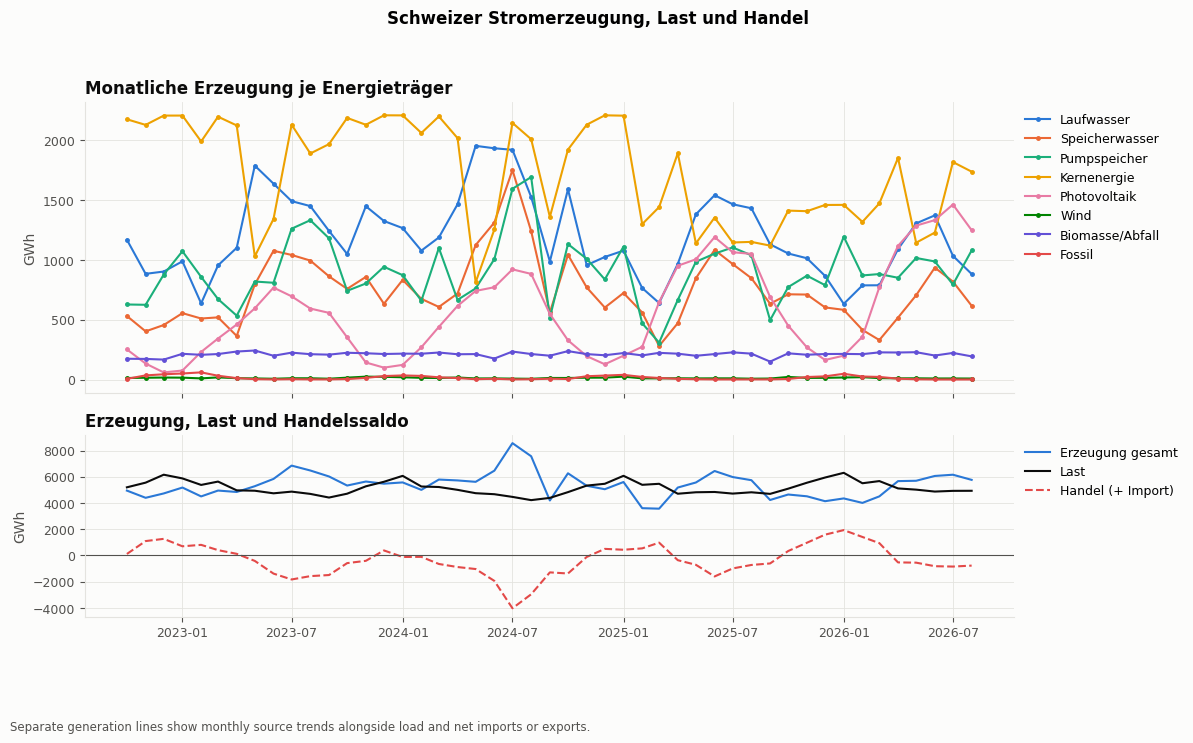

In [21]:
gen_m = (gen * step_h).tz_convert(TZ).resample("MS").sum() / 1e3  # GWh
load_m = (power["Last"] * step_h).tz_convert(TZ).resample("MS").sum() / 1e3
trade_m = (power["Grenzüberschreitender Stromhandel"] * step_h).tz_convert(TZ).resample("MS").sum() / 1e3
# Laufender Monat ist bei Pronovo noch nicht publiziert
last_full = (power.index.max() + pd.Timedelta("15min")).tz_convert(TZ).normalize().replace(day=1)
gen_m, load_m, trade_m = gen_m[gen_m.index < last_full], load_m[load_m.index < last_full], trade_m[trade_m.index < last_full]

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for i, col in enumerate(gen_m.columns):
    axes[0].plot(gen_m.index, gen_m[col], color=COLORS[i % len(COLORS)], label=col, marker="o", markersize=2.5)
axes[0].set_title("Monatliche Erzeugung je Energieträger")
axes[0].set_ylabel("GWh")
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

axes[1].plot(gen_m.index, gen_m.sum(axis=1), color=COLORS[0], label="Erzeugung gesamt")
axes[1].plot(load_m.index, load_m, color=INK, label="Last")
axes[1].plot(trade_m.index, trade_m, color=COLORS[7], linestyle="--", label="Handel (+ Import)")
axes[1].axhline(0, color=INK_2, linewidth=0.8)
axes[1].set_title("Erzeugung, Last und Handelssaldo")
axes[1].set_ylabel("GWh")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Schweizer Stromerzeugung, Last und Handel", fontweight="bold")
save(fig, "08_strommix_monat.png", "Separate generation lines show monthly source trends alongside load and net imports or exports.")

### 4.5 Tagesprofile der Erzeugung (Sommer vs. Winter, letztes volles Jahr)

**Grafik: Winter- und Sommerproduktion.** Jede Produktionsart erscheint als eigene
Medianlinie mit P25–P75-Band je Lokalzeitstunde. Winter umfasst Dezember, Januar und
Februar desselben Kalenderjahres, also keinen zusammenhängenden meteorologischen Winter.

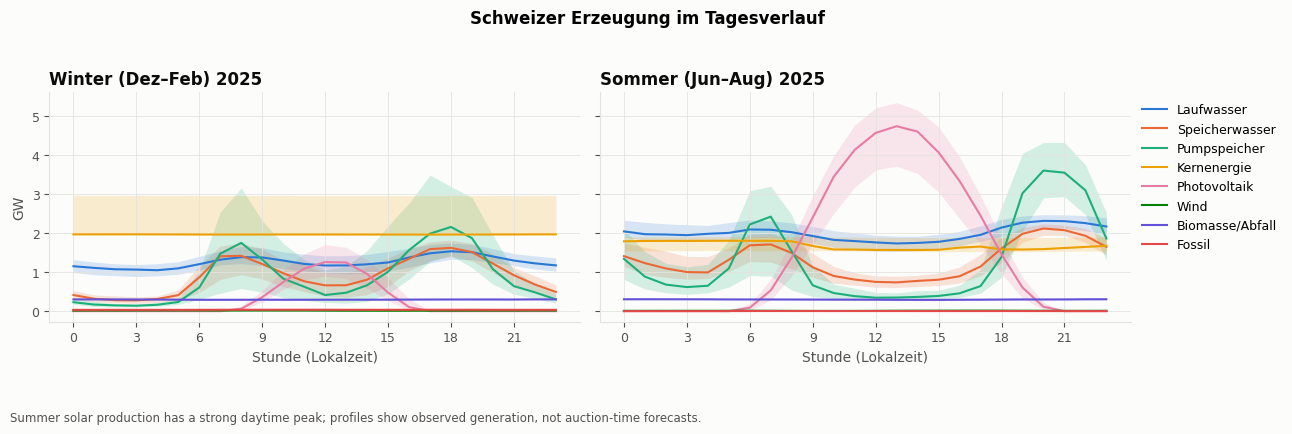

In [22]:
last_year = int(energy_y.index[-2]) if NOW.year in energy_y.index else int(energy_y.index[-1])
sub = gen[gen.index.tz_convert(TZ).year == last_year] / 1e3  # GW
loc = sub.index.tz_convert(TZ)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, months, title in zip(axes, ([12, 1, 2], [6, 7, 8]), ("Winter (Dez–Feb)", "Sommer (Jun–Aug)")):
    m = np.isin(loc.month, months)
    q = sub[m].groupby(loc[m].hour).quantile([0.25, 0.5, 0.75]).unstack()
    for i, col in enumerate(sub.columns):
        c = COLORS[i % len(COLORS)]
        ax.fill_between(q.index, q[(col, 0.25)], q[(col, 0.75)], color=c, alpha=0.18, linewidth=0)
        ax.plot(q.index, q[(col, 0.5)], color=c, label=col)
    ax.set_title(f"{title} {last_year}")
    ax.set_xlabel("Stunde (Lokalzeit)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("GW")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Schweizer Erzeugung im Tagesverlauf", fontweight="bold")
save(fig, "09_erzeugung_tagesprofil.png", "Summer solar production has a strong daytime peak; profiles show observed generation, not auction-time forecasts.")

## 5 Zusammenhang Preis ↔ Erzeugung

Beide Quellen werden auf Stunden (UTC) gebracht und über den Zeitstempel verbunden. Abgeleitete Grössen:

- **Residuallast CH** = Last − Photovoltaik − Wind (was steuerbare Kraftwerke oder Import decken müssen)
- **Handel** = grenzüberschreitender Stromhandel (+ = Nettoimport)
- **Pumpspeicher netto** = Erzeugung + Verbrauch (Verbrauch ist negativ)

**Einordnung:** Der Preis wurde am Vortag aus Prognosen festgelegt, die Pronovo-Werte sind die später gemessene
Produktion. Die Zusammenhänge zeigen also, welche Grössen die Auktion einpreist (Reverse-Engineering), verwässert
durch den Prognosefehler des Marktes. Für unsere Prognose von Tag D+2 stehen diese Grössen nur als Prognosen
(Solar, Wind, Last) zur Verfügung.

In [23]:
hourly = pd.concat([gen.resample("1h").mean(),
                    power[["Last", "Grenzüberschreitender Stromhandel", "Pumpspeicher Verbrauch"]].resample("1h").mean(),
                    price_h[["price", "volume", "hour", "month"]]], axis=1, join="inner").dropna(subset=["price"])
hourly["Residuallast CH"] = hourly["Last"] - hourly["Photovoltaik"] - hourly["Wind"]
hourly["Pumpspeicher netto"] = hourly["Pumpspeicher"] + hourly["Pumpspeicher Verbrauch"]
hourly = hourly.rename(columns={"Grenzüberschreitender Stromhandel": "Handel (+ Import)"})
print(f"Gemeinsamer Zeitraum: {hourly.index.min():%Y-%m-%d} – {hourly.index.max():%Y-%m-%d}, {len(hourly):,} Stunden")

print("Pronovo-Daten ab 01.10.2022 (vollständiges Schema)")
drivers = ["Residuallast CH", "Last", "Photovoltaik", "Wind", "Laufwasser", "Speicherwasser", "Pumpspeicher",
           "Pumpspeicher Verbrauch", "Pumpspeicher netto", "Kernenergie", "Handel (+ Import)", "volume"]
corr = pd.DataFrame({
    "Spearman ρ (ab 10/2022)": [hourly[[d, "price"]].corr(method="spearman").iloc[0, 1] for d in drivers],
    "Spearman ρ (ab 2024)": [hourly.loc["2024":, [d, "price"]].corr(method="spearman").iloc[0, 1] for d in drivers],
}, index=drivers).sort_values("Spearman ρ (ab 2024)", key=np.abs, ascending=False)
corr

Gemeinsamer Zeitraum: 2022-09-30 – 2026-08-31, 34,344 Stunden
Pronovo-Daten ab 01.10.2022 (vollständiges Schema)


,Spearman ρ (ab 10/2022),Spearman ρ (ab 2024)
Residuallast CH,0.57,0.55
Pumpspeicher Verbrauch,0.50,0.53
Pumpspeicher netto,0.43,0.47
Laufwasser,-0.38,-0.37
Pumpspeicher,0.33,0.36
Photovoltaik,-0.27,-0.29
Last,0.33,0.26
volume,0.02,0.10
Speicherwasser,0.05,0.08
Handel (+ Import),0.06,0.06


**Grafik: Rangkorrelation mit dem CH-Preis (ab 2024).** Positive Werte bedeuten höhere Preise bei höheren Messwerten, negative das Gegenteil. Die später gemessenen Werte sind nur rückblickende Proxys der Markterwartungen.

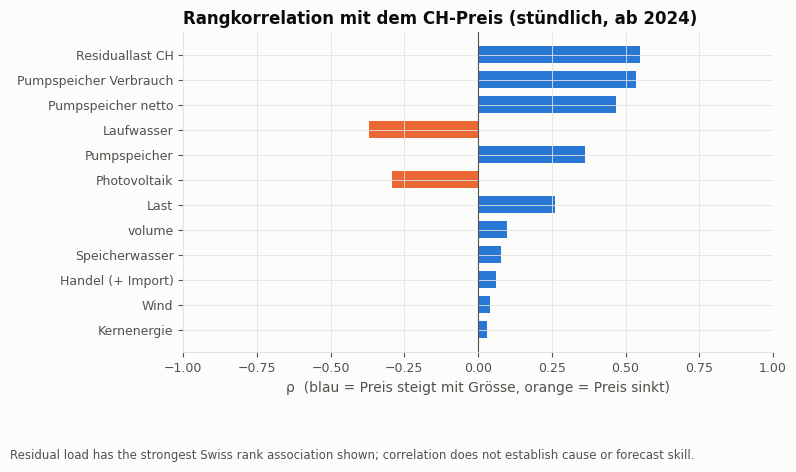

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
t = corr["Spearman ρ (ab 2024)"].iloc[::-1]
ax.barh(t.index, t, color=[COLORS[0] if v >= 0 else COLORS[1] for v in t], height=0.65)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_title("Rangkorrelation mit dem CH-Preis (stündlich, ab 2024)")
ax.set_xlabel("ρ  (blau = Preis steigt mit Grösse, orange = Preis sinkt)")
save(fig, "10_korrelationen.png", "Residual load has the strongest Swiss rank association shown; correlation does not establish cause or forecast skill.")

**Grafik: Preis und Schweizer Treiber.** Punkte zeigen Stunden ab 2024, schwarze Linien
die Mediane von 25 gleich häufigen Klassen. Die y-Achse zeigt P0.2–P99.8 zur Lesbarkeit;
Extremwerte bleiben im Datensatz und in den Statistiken. Wasserkraft und Pumpspeicher
können ihre Fahrpläne an den bekannten Preis anpassen; daraus folgt keine eindeutige
Wirkungsrichtung. Wegen der Pronovo-Verzögerung reicht ein kurzer Lag nicht als Live-Feature.

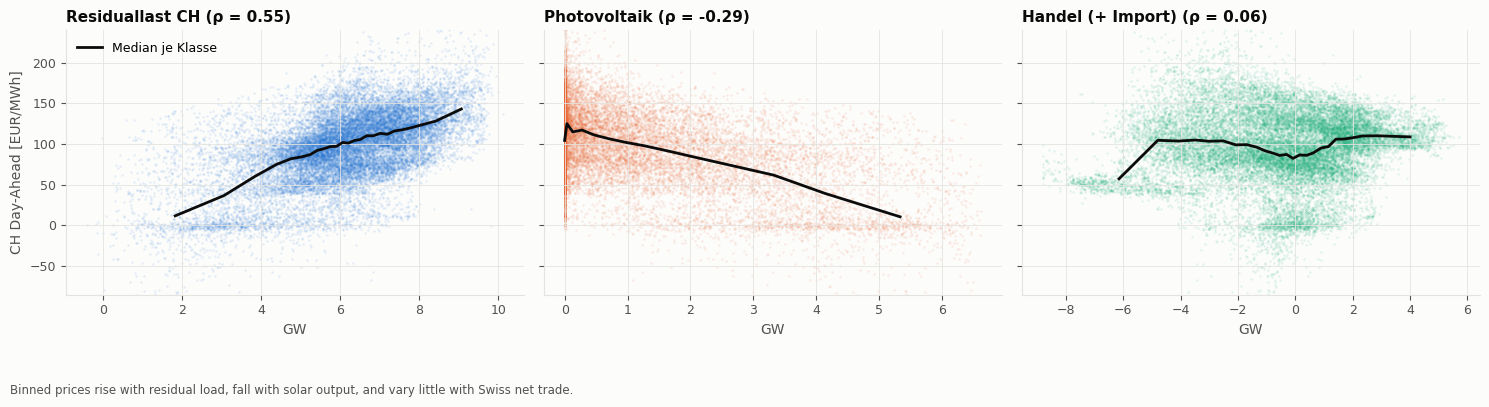

In [25]:
recent_j = hourly.loc["2024":]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, col, color in zip(axes, ["Residuallast CH", "Photovoltaik", "Handel (+ Import)"], COLORS):
    pair = recent_j[[col, "price"]].dropna()
    ax.scatter(pair[col] / 1e3, pair["price"], s=3, alpha=0.12, color=color, linewidths=0)
    bins = pd.qcut(pair[col], 25, duplicates="drop")
    med = pair.groupby(bins, observed=True).median()
    ax.plot(med[col] / 1e3, med["price"], color=INK, linewidth=2, label="Median je Klasse")
    ax.set_title(f"{col} (ρ = {pair.corr(method='spearman').iloc[0, 1]:.2f})", fontsize=11)
    ax.set_xlabel("GW")
axes[0].set_ylabel("CH Day-Ahead [EUR/MWh]")
axes[0].set_ylim(recent_j["price"].quantile(0.002), recent_j["price"].quantile(0.998))
axes[0].legend(loc="upper left")
save(fig, "11_scatter_treiber.png", "Binned prices rise with residual load, fall with solar output, and vary little with Swiss net trade.")

### 5.1 Tagesprofil Residuallast vs. Preis

**Grafik: Residuallast und Day-Ahead-Preis im Winter und Sommer.** Residuallast =
Last − PV − Wind. Median und P25–P75 zeigen, wie ein sommerliches Mittagstal in beiden
Reihen auftritt. Preis und Residuallast haben getrennte Einheiten und Achsen;
ähnliche Formen allein sind kein Beleg für identische Dynamik oder Kausalität.

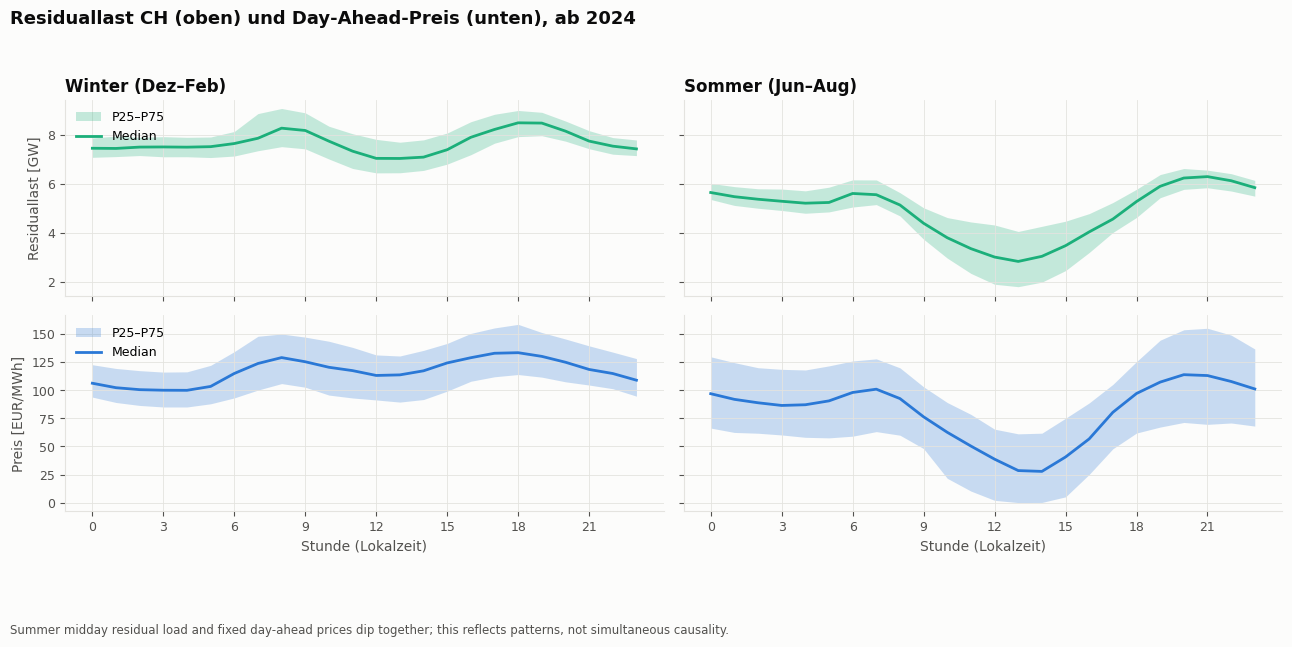

In [26]:
loc_j = recent_j.index.tz_convert(TZ)
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey="row")
for c, (months, title) in enumerate((([12, 1, 2], "Winter (Dez–Feb)"), ([6, 7, 8], "Sommer (Jun–Aug)"))):
    m = np.isin(loc_j.month, months)
    for r, (col, scale, unit, color) in enumerate((("Residuallast CH", 1e3, "Residuallast [GW]", COLORS[2]),
                                                   ("price", 1, "Preis [EUR/MWh]", COLORS[0]))):
        q = (recent_j.loc[m, col] / scale).groupby(loc_j[m].hour).quantile([0.25, 0.5, 0.75]).unstack()
        ax = axes[r, c]
        ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.25, linewidth=0, label="P25–P75")
        ax.plot(q.index, q[0.5], color=color, linewidth=2, label="Median")
        ax.set_xticks(range(0, 24, 3))
        if c == 0:
            ax.set_ylabel(unit)
        if r == 0:
            ax.set_title(title)
        else:
            ax.set_xlabel("Stunde (Lokalzeit)")
for r in range(2):
    axes[r, 0].legend(loc="upper left")
fig.suptitle("Residuallast CH (oben) und Day-Ahead-Preis (unten), ab 2024", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
save(fig, "14_residuallast_preis_tagesprofil.png", "Summer midday residual load and fixed day-ahead prices dip together; this reflects patterns, not simultaneous causality.")

### 5.2 Mittagspreis und Solarproduktion

**Grafik: Median-Mittagspreis nach PV-Leistung.** Stunden 11–15 Uhr ab 2024 werden
in 0.5-GW-Klassen zusammengefasst (mindestens 30 Beobachtungen je Klasse).
Eine negative Beziehung ist mit eingepreister erwarteter Sonne vereinbar; spätere
Ist-Produktion, saisonale Nachfrage und regionale Märkte sind nicht kausal getrennt.

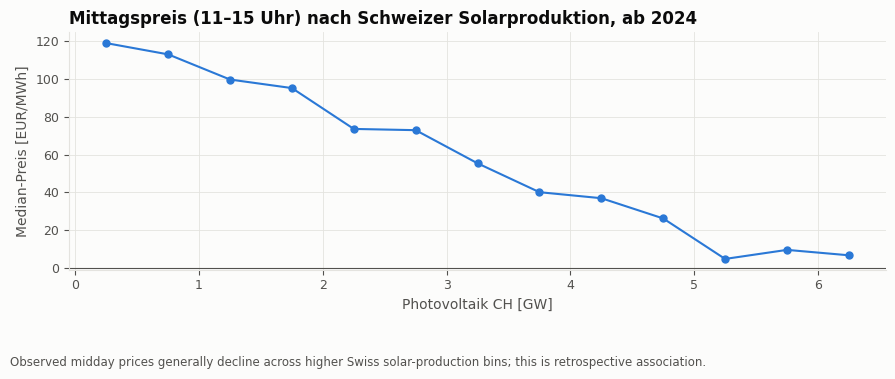

In [27]:
noon = recent_j[recent_j["hour"].between(11, 15)][["Photovoltaik", "price"]].dropna()
bins = pd.cut(noon["Photovoltaik"] / 1e3, np.arange(0, noon["Photovoltaik"].max() / 1e3 + 0.5, 0.5))
g = noon.groupby(bins, observed=True)["price"].agg(["median", "count"])
g = g[g["count"] >= 30]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([b.mid for b in g.index], g["median"], marker="o", markersize=5, color=COLORS[0])
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("Mittagspreis (11–15 Uhr) nach Schweizer Solarproduktion, ab 2024")
ax.set_xlabel("Photovoltaik CH [GW]")
ax.set_ylabel("Median-Preis [EUR/MWh]")
save(fig, "12_solar_mittagspreis.png", "Observed midday prices generally decline across higher Swiss solar-production bins; this is retrospective association.")

### 5.3 Solar und Wind im direkten Vergleich

**Grafik: PV und Wind als rückblickende Preis-Proxys.** Identischer Zeitraum und gleiche
Preisachse ermöglichen den Vergleich. Die Kurven zeigen Medianpreise in gleich häufigen
Leistungsklassen. Ein schwacher Zusammenhang mit Schweizer Wind sagt nichts über
Wind in Deutschland oder anderen Nachbarmärkten aus.

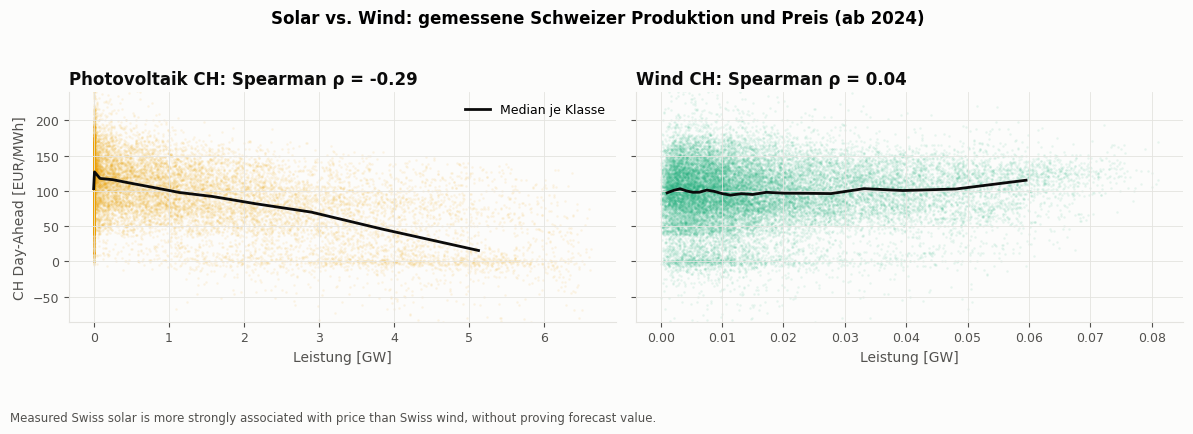

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, col, color in zip(axes, ["Photovoltaik", "Wind"], [COLORS[3], COLORS[2]]):
    pair = recent_j[[col, "price"]].dropna()
    rho = pair.corr(method="spearman").iloc[0, 1]
    ax.scatter(pair[col] / 1e3, pair["price"], s=3, alpha=0.1, color=color, linewidths=0)
    bins = pd.qcut(pair[col], 20, duplicates="drop")
    med = pair.groupby(bins, observed=True).median()
    ax.plot(med[col] / 1e3, med["price"], color=INK, linewidth=2, label="Median je Klasse")
    ax.set_title(f"{col} CH: Spearman ρ = {rho:.2f}")
    ax.set_xlabel("Leistung [GW]")
axes[0].set_ylabel("CH Day-Ahead [EUR/MWh]")
axes[0].set_ylim(recent_j["price"].quantile(0.002), recent_j["price"].quantile(0.998))
axes[0].legend()
fig.suptitle("Solar vs. Wind: gemessene Schweizer Produktion und Preis (ab 2024)", fontweight="bold")
save(fig, "15_solar_wind.png", "Measured Swiss solar is more strongly associated with price than Swiss wind, without proving forecast value.")

### 5.4 Autokorrelation des Preises

Wie stark hängt der Preis von seinen eigenen Vergangenheitswerten ab? Die Lags 24 h (Vortag) und 168 h
(Vorwoche) sind die Grundlage der naiven Baselines und der Lag-Features im Modell.

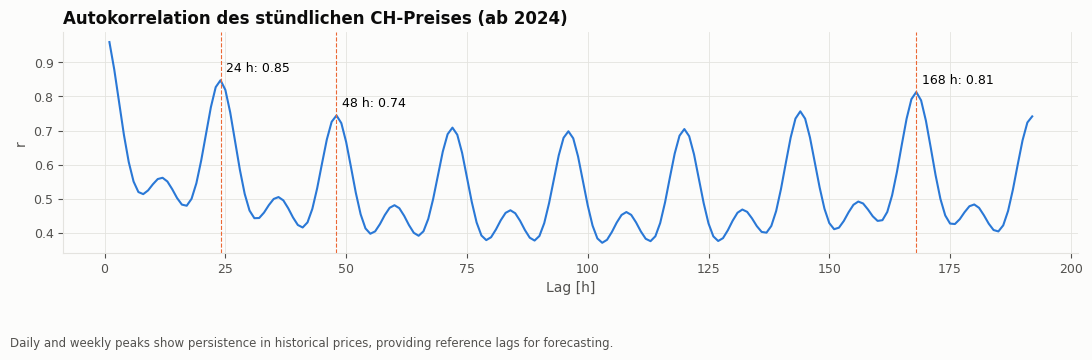

In [29]:
s = price_h.loc["2024":, "price"].asfreq("1h")
lags = range(1, 24 * 8 + 1)
acf = pd.Series([s.autocorr(l) for l in lags], index=lags)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(acf.index, acf, color=COLORS[0])
for l in (24, 48, 168):
    ax.axvline(l, color=COLORS[1], linewidth=0.8, linestyle="--")
    ax.annotate(f"{l} h: {acf[l]:.2f}", (l, acf[l]), textcoords="offset points", xytext=(4, 6), fontsize=9)
ax.set_title("Autokorrelation des stündlichen CH-Preises (ab 2024)")
ax.set_xlabel("Lag [h]")
ax.set_ylabel("r")
save(fig, "13_autokorrelation.png", "Daily and weekly peaks show persistence in historical prices, providing reference lags for forecasting.")

### 5.5 Naive Baselines als Referenz für das Ziel nMAE < 10 %

`nMAE = MAE / mittlerer Absolutpreis`. Die Tabelle ist eine deskriptive Referenz,
keine zeitpunktgerechte D+2-Validierung. Bei Prognose nach der Auktion an Tag D
ist D+1 bekannt: Für eine Zielstunde an D+2 liegt deren **24h-Lag an D+1**
und ist bereits verfügbar. 48h-Persistenz ist eine weitere Vergleichsbasis, nicht
die einzig zulässige. Bei einem rollierenden Horizont muss die Verfügbarkeit für
jede Zielstunde separat geprüft werden; UTC-Lags verschieben an Zeitumstellungstagen
die Lokalzeit. Eine echte Evaluation muss den Ausgabezeitpunkt, verfügbare D+2-Features
und den Vergleich „24h bekannt“ versus „48h mit Prognose“ nachbilden.

In [30]:
def nmae(y, yhat):
    pair = pd.concat([y, yhat], axis=1).dropna()
    return 100 * (pair.iloc[:, 0] - pair.iloc[:, 1]).abs().mean() / pair.iloc[:, 0].abs().mean()


s_all = price_h["price"].asfreq("1h")
yr = s_all.index.tz_convert(TZ).year
base = pd.DataFrame({f"nMAE Persistenz {h} h [%]": s_all.groupby(yr).apply(lambda y, h=h: nmae(y, s_all.shift(h).loc[y.index]))
                     for h in (24, 48, 168)})
base

,nMAE Persistenz 24 h [%],nMAE Persistenz 48 h [%],nMAE Persistenz 168 h [%]
time_utc,,,
2015,15.28,21.24,14.07
2016,15.16,21.63,14.37
2017,13.25,19.21,15.10
2018,12.53,17.18,14.80
2019,13.71,18.28,15.08
2020,16.96,23.89,17.75
2021,13.17,18.82,18.30
2022,12.62,18.40,22.61
2023,14.96,20.95,19.05


## 6 Fazit und Grenzen

Die berechneten Tabellen und Grafiken belegen Abdeckung, Schemawechsel, Preisregime,
Tages-/Wochenstruktur und rückblickende Zusammenhänge. Die Preisreihe ist die Zielgrösse;
Pronovo erklärt die Schweizer Seite, wird aber verzögert veröffentlicht und ersetzt keine
archivierten, zum jeweiligen Ausgabezeitpunkt verfügbaren Prognosen.

Solar und Residuallast enthalten hier stärkere Signale als Schweizer Wind.
Das darf nicht auf europäischen Wind verallgemeinert werden. Korrelationsstärke ist kein
Out-of-sample-Prognosenachweis. Die EDA rekonstruiert Markterwartungen nur indirekt.

Ein EMS kann den veröffentlichten Liefertag schon ohne Modell optimieren.
Ein 48h-Profil muss den zusätzlichen zweiten Tag gegen diesen **Known-price-Benchmark**
bewerten. Die bestehenden Modellresultate in `analysis/` betreffen eine andere
Prognosesituation und validieren das vorgeschlagene D+2-Ziel noch nicht.
Keine feste CHF-Einsparung und keine künftige Häufigkeit negativer Preise werden aus
dieser EDA garantiert. Die aktuellen Zahlen stehen im README und im folgenden Export.

### 6.1 Reproduzierbare Kennzahlen für den Bericht

Der JSON-Export speichert die tatsächlich berechneten Werte, Zeiträume und Definitionen.
Zeitlücken beziehen sich auf das UTC-Raster; Anteile beziehen sich auf vorhandene
Beobachtungen. 2026 ist ein Teiljahr. Ein Cache-Manifest dokumentiert SHA-256-Prüfsummen
der geladenen Jahresdateien, damit Änderungen der Datenbasis erkennbar bleiben.

In [31]:
import hashlib
import importlib.metadata

def data_quality(df, freq):
    grid = pd.date_range(df.index.min(), df.index.max(), freq=freq)
    return {
        "start": df.index.min().isoformat(), "end": df.index.max().isoformat(),
        "rows": len(df), "missing_timestamps": len(grid.difference(df.index)),
        "missing_values": {c: int(v) for c, v in df.isna().sum().items()},
    }

raw_power = pd.concat([to_frame(json.loads((RAW / "power_pronovo" / f"{y}.json").read_text(encoding="utf-8")))
                       for y in POWER_YEARS]).sort_index()
raw_power = raw_power[~raw_power.index.duplicated(keep="last")]
raw_power = raw_power[raw_power.index < END]
quality_stats = {"price": data_quality(price, "1h"), "power": data_quality(raw_power, "15min")}
spread_stats = spread.groupby(spread.index.year).agg(["mean", "median", "max"])
profile_export = profile_summary.reset_index().to_dict(orient="records")
week_stats = week.groupby("weekday")["price"].agg(["median", "mean", "count"])
recent_seasonal_price = {}
for season, months in (("Winter", [12, 1, 2]), ("Sommer", [6, 7, 8])):
    mask = recent_j.index.tz_convert(TZ).month.isin(months)
    values = recent_j.loc[mask, "price"]
    profile = values.groupby(values.index.tz_convert(TZ).hour).median()
    recent_seasonal_price[season] = {"hourly_median": profile.to_dict(),
                                     "profile_spread": float(profile.max() - profile.min())}
manifest = {
    str(p.relative_to(RAW)): hashlib.sha256(p.read_bytes()).hexdigest()
    for kind, years in (("power_pronovo", POWER_YEARS), ("price_dayahead", PRICE_YEARS))
    for y in years for p in [RAW / kind / f"{y}.json"]
}
stats = {
    "report_cutoff": NOW.date().isoformat(),
    "executed_at": pd.Timestamp.now(tz="UTC").isoformat(),
    "quality": quality_stats,
    "yearly_price": yearly.to_dict(orient="index"),
    "daily_spread": spread_stats.to_dict(orient="index"),
    "daily_profiles_without_2022_2023": profile_export,
    "profile_iqr": width.to_dict(orient="index"),
    "weekday_since_2024": week_stats.to_dict(orient="index"),
    "seasonal_price_on_joint_period_since_2024": recent_seasonal_price,
    "spearman": corr.to_dict(orient="index"),
    "pv_share_percent": table["PV-Anteil %"].to_dict(),
    "monthly_trade_GWh": {"min": float(trade_m.min()), "max": float(trade_m.max())},
    "autocorrelation": {str(h): float(acf[h]) for h in (24, 48, 168)},
    "baseline_nmae_percent": base.to_dict(orient="index"),
    "cache_sha256": manifest,
    "environment": {p: importlib.metadata.version(p) for p in
                    ("numpy", "pandas", "matplotlib", "requests", "nbformat", "nbclient", "ipykernel", "tabulate", "scipy")},
}
(FIG / "summary_statistics.json").write_text(json.dumps(stats, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
display(pd.DataFrame({k: {c: v for c, v in d.items() if c != "missing_values"}
                      for k, d in quality_stats.items()}).T)
print("Kennzahlen: figures/eda/summary_statistics.json")

,start,end,rows,missing_timestamps
price,2014-12-31T23:00:00+00:00,2026-10-30T22:00:00+00:00,103704,0
power,2019-12-31T23:00:00+00:00,2026-08-31T21:45:00+00:00,233756,0


Kennzahlen: figures/eda/summary_statistics.json


### 6.2 Abschlussprüfungen

Die Prüfungen machen unerwartete Änderungen der Datenbasis sichtbar: eindeutige UTC-Indizes,
vollständiges Raster, keine verlorenen Preisstunden, geordnete Quantile und lesbare Exporte.
Jede PNG muss im Bericht eingebunden sein; die Prüfungen ersetzen keine fachliche Validierung.

In [32]:
import re

for frame in (price, raw_power):
    assert frame.index.is_unique and frame.index.is_monotonic_increasing
    assert str(frame.index.tz) == "UTC"
assert all(d["missing_timestamps"] == 0 for d in quality_stats.values())
assert price["price"].notna().all()
assert len(price_h) == len(price)
assert (price_h["price"] < 0).sum() == (price["price"] < 0).sum()
assert price_h["volume"].isna().sum() == price["volume"].isna().sum()
for q in (q_all, q_nc):
    assert (q["P25"] <= q["P50"]).all() and (q["P50"] <= q["P75"]).all()
readme = (ROOT / "README.md").read_text(encoding="utf-8")
linked = set(re.findall(r"!\[[^\]]*\]\((figures/eda/[^)]+\.png)\)", readme))
exported = {p.relative_to(ROOT).as_posix() for p in FIG.glob("*.png")}
assert linked == exported, f"Bericht/Export unterscheiden sich: {linked ^ exported}"
for image in exported:
    height, width = plt.imread(ROOT / image).shape[:2]
    assert width >= 1400 and height >= 600, (image, width, height)
print(f"Alle Datenprüfungen bestanden; {len(exported)} PNGs im README eingebunden.")
expected_figures = {
    "00_datenqualitaet.png", "01_preis_zeitverlauf.png", "02_preis_verteilung.png",
    "03_tagesprofile_perzentile.png", "03b_tagesprofile_perzentile_ohne_2022_2023.png",
    "04_wochenmuster.png", "05_tagesspanne.png", "07_pv_anteil.png",
    "08_strommix_monat.png", "09_erzeugung_tagesprofil.png", "10_korrelationen.png",
    "11_scatter_treiber.png", "12_solar_mittagspreis.png", "13_autokorrelation.png",
    "14_residuallast_preis_tagesprofil.png", "15_solar_wind.png",
}
assert set(FIGURE_INFO) == expected_figures, set(FIGURE_INFO) ^ expected_figures
assert all(item["title"].strip() and item["description"].strip()
           for item in FIGURE_INFO.values())
for name in expected_figures:
    assert (FIG / name).is_file()


Alle Datenprüfungen bestanden; 16 PNGs im README eingebunden.
